In [1]:
%pip install jax optax scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import socket
import sys

import jax
jax.config.update("jax_enable_x64", True) 

import jax.numpy as jnp
import optax
import numpy as np
import matplotlib.pyplot as plt

print("Machine:", socket.gethostname())
print("JAX backend:", jax.default_backend())
print("JAX devices:", jax.devices())
print("jax_enable_x64:", jax.config.read("jax_enable_x64"))
print("Example array dtype:", jnp.ones(1).dtype)
print("Python:", sys.version.split()[0])
print("JAX:", jax.__version__)
print("NumPy:", np.__version__)
print("Optax:", optax.__version__)

Machine: Muid
JAX backend: cpu
JAX devices: [CpuDevice(id=0)]
jax_enable_x64: True
Example array dtype: float64
Python: 3.14.6
JAX: 0.12.1
NumPy: 2.4.6
Optax: 0.2.9


# Mini-Lab 2: Getting Started with JAX and Optax

**Due:** Monday, November 16, 2026 (show your work in class if possible; or upload it before the end of day. This lab is meant to directly help with HW 6)

**Key idea:** JAX lets us differentiate numerical models, and Optax uses those derivatives to update model parameters as part of training. We'll practice on an optimization problem and linear regression before you tackle polynomial regression and neural networks in **Homework 6**.

By the end of this lab, you should be able to do the following in JAX: write a loss function, calculate its gradient, train using Optax, and interpret training and testing MSE.

## Part I - Computing environment, arrays, and decorators

For this lab, please consider working on **Unity**, **Colab**, or another appropriate computing environment rather than a personal laptop. This is mostly for you to get experience with HPC systems, rather than a hard requirement. 

If using Unity, launch JupyterLab on a **compute node**, not the login node.

Unity setup instructions: [MTH 602: deep-learning environments](https://github.com/sfield17/MTH602-Fall2026-SciML/blob/main/README.md#deep-learning-environment-setups).

1. Start your Jupyter session and select your JAX/Optax kernel (for example, `mth602-jax-env`).
2. Run the following setup cell. Show your machine name and package/precision information to Scott.

We use **64-bit floating-point numbers** for the lab. JAX normally defaults to 32-bit; Homework 6 asks you to report which precision you used. Run the configuration cell before any other JAX array computations.

### NumPy and JAX arrays

Most `jax.numpy` operations look like NumPy operations. One important difference is that JAX arrays are **immutable**. This means that if a calculation modifies an array a new array is created. Changing existing arrays is not allowed in JAX. This is actually a key to its computational performance benefits.

JAX also provides transformations such as `jax.grad` and `jax.jit`, which we will see below

In [3]:
# arrays in numpy. Notice that "b=a" is a reference to the same underlying array data!

a = np.array([1.0, 2.0, 3.0])

b = a
b[0] = 10

print("b:  ", b)
print("a (changed!):", a)

b:   [10.  2.  3.]
a (changed!): [10.  2.  3.]


In [4]:
# arrays in numpy. if you want to modify b without modifying a, you need a copy

a = np.array([1.0, 2.0, 3.0])

b = np.copy(a)
b[0] = 10

print("b:  ", b)
print("a:", a)

b:   [10.  2.  3.]
a: [1. 2. 3.]


In [5]:
# in Jax, arrays are copied whenever modified

a = jnp.array([1.0, 2.0, 3.0])
b = a.at[0].set(10.0)  # this statement will copy the data in "a" and change its value
print("a (unchanged):", a)
print("b (updated):  ", b)

a (unchanged): [1. 2. 3.]
b (updated):   [10.  2.  3.]


### Python decorators and `@jax.jit`

In Python, a **decorator** is a function that takes another function as input and returns a modified version of it. 

Decorators are applied using the `@` syntax.

We will often encounter dectorators in JAX, and they work the same way. For example, `@jax.jit` takes a Python function and returns a version that JAX can just-in-time (JIT) compile for faster execution.

In [6]:
# Here's a simple decorator 
def my_decorator(func):
    def wrapper(x):
        print("Before calling the function")
        result = func(x)
        print("After calling the function")
        return result
    return wrapper

# Apply the decorator to modify the behavior of square(x)
@my_decorator
def square(x):
    return x**2

print(square(3))

Before calling the function
After calling the function
9


## Part II — Demo: minimizing a 2D function

Consider the familiar objective function

$$
f(\boldsymbol{w}) = w_0^2+w_1^2, \qquad
\nabla f(\boldsymbol{w})=(2w_0,2w_1).
$$

The minimum is at $\boldsymbol{w}=(0,0)$. We will assume we don't know this and numerically find it through optimization. 

First, we will need to define our objective function and compute a gradient. We want computations to be fast, so we will also ask JAX to just-in-time (JIT) compile our python code into a faster low-level kernel.

1. `jax.grad(f)` returns a function that computes the derivative 
2. `jax.value_and_grad(f)` returns *both* the value and gradient
3. `jax.jit(...)` compiles a function for faster repeated execution.

In [7]:
def quadratic(w):
    """ ordinary python function for the objective function"""
    return w[0]**2 + w[1]**2

In [8]:
# we ask jax to "fuse" the gradient and function call
quadratic_and_grad = jax.value_and_grad(quadratic)


w0        = jnp.array([2.5, -2.0])
f0, grad0 = quadratic_and_grad(w0)

print("Function value:", f0)
print("Gradient from JAX:", grad0)
print("Gradient from calculus:", 2 * w0)

Function value: 10.25
Gradient from JAX: [ 5. -4.]
Gradient from calculus: [ 5. -4.]


In [9]:
# the code above is still pure-python, so slow. We now ask JAX to compile it into a faster version (JIT-ed)
quadratic_and_grad_jit = jax.jit(quadratic_and_grad)

f0, grad0 = quadratic_and_grad_jit(w0)

print("Function value:", f0)
print("Gradient from JAX:", grad0)
print("Gradient from calculus:", 2 * w0)

Function value: 10.25
Gradient from JAX: [ 5. -4.]
Gradient from calculus: [ 5. -4.]


### Gradient descent with Optax

For gradient descent,

$$
\boldsymbol{w}_{k+1}=\boldsymbol{w}_{k}-\alpha\nabla f(\boldsymbol{w}_k).
$$

Optax implements the update through three operations:

1. initialize optimizer state (`init`)
2. calculate an update (`update`)
3. apply the update to the parameters (`apply_updates`)

With `optax.sgd` and no momentum, using the **entire** dataset is ordinary *full-batch gradient descent*. The same optimizer becomes stochastic/mini-batch gradient descent when the gradient comes from a randomly selected batch.

In [10]:
# Specify the optimization method to use and its parameters (here, the learning rate)
optimizer_2d = optax.sgd(learning_rate=0.1)


# Input: in the current parameters w=(w1, w2) and the optimizers state (holds information about the optimizer)
# Output: the updated parameters w=(w1, w2) and the updated optimizer's state
# we also have JAX compile this function so its fast
@jax.jit
def quadratic_step(w, opt_state):
    _, gradient = quadratic_and_grad_jit(w)
    updates, opt_state = optimizer_2d.update(gradient, opt_state, w)
    w = optax.apply_updates(w, updates)
    return w, opt_state

In [11]:
# initialize the starting point for the weights, and the optimizer
w = w0
opt_state = optimizer_2d.init(w)
weight_path = [np.asarray(w)]
objective_path = [quadratic(w)]

epochs = 40 # number of weight updates
for _ in range(epochs):
    w, opt_state = quadratic_step(w, opt_state)
    weight_path.append(np.asarray(w))
    objective_path.append(quadratic(w))

weight_path = np.asarray(weight_path)
objective_path = np.asarray(objective_path)
print("Final weights:", w)

Final weights: [ 0.00033231 -0.00026585]


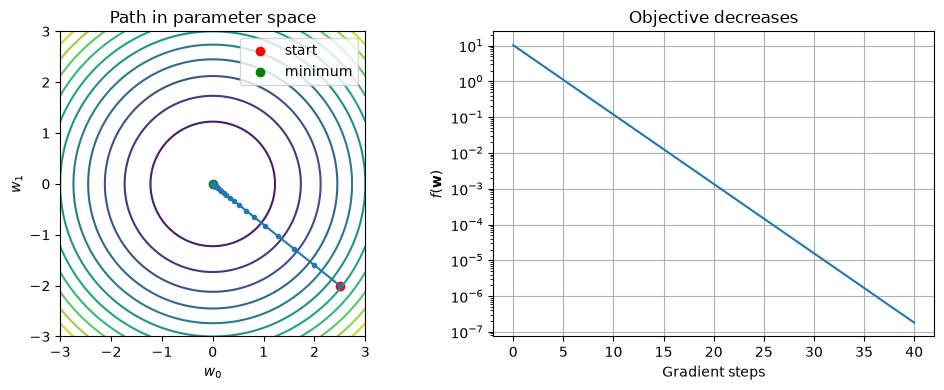

In [12]:
# Plot the results
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

xx, yy = np.meshgrid(np.linspace(-3, 3, 100), np.linspace(-3, 3, 100))
ax[0].contour(xx, yy, xx**2 + yy**2, levels=15)
ax[0].plot(weight_path[:, 0], weight_path[:, 1], "o-", ms=3)
ax[0].scatter(weight_path[0, 0], weight_path[0, 1], color="red", label="start")
ax[0].scatter(0, 0, color="green", label="minimum")
ax[0].set(xlabel="$w_0$", ylabel="$w_1$", title="Path in parameter space")
ax[0].set_aspect("equal")
ax[0].legend()

ax[1].semilogy(np.arange(len(objective_path)), objective_path)
ax[1].set(xlabel="Gradient steps", ylabel="$f(\\mathbf{w})$", title="Objective decreases")
ax[1].grid(True)
plt.tight_layout()
plt.show()

## Part III — Demo: regression in JAX

We now fit noisy observations of a straight line,

$$
y(x)\approx a+bx.
$$

Written as a least-squares problem:

$$
\boldsymbol{\hat y}=A\boldsymbol{\omega},\quad
A=\begin{bmatrix}1&x_1\\\vdots&\vdots\\1&x_N\end{bmatrix},\quad
\boldsymbol{\omega}=\begin{bmatrix}a\\b\end{bmatrix},
$$

with mean-squared-error loss

$$
J(\boldsymbol{\omega})=\frac1N\sum_{i=1}^N
\bigl((A\boldsymbol{\omega})_i-y_i\bigr)^2.
$$

The same code will work for polynomials of degree by changing the design matrix to columns. **This is a key HW6 Hint!!!**

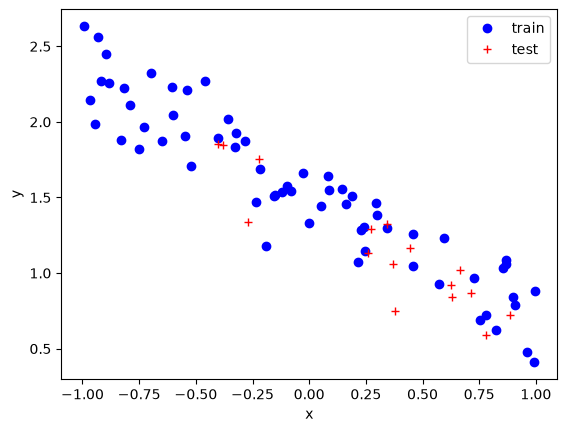

In [13]:
# numpy is fine for generating/splitting data
# We will then covert numpy arrays to convert to JAX arrays for training.

# rng = random number generator
rng            = np.random.default_rng(0)

# dataset
num_points     = 80
a_true, b_true = 1.5, -0.8
x_all          = rng.uniform(-1.0, 1.0, num_points)
y_all          = a_true + b_true * x_all + 0.2 * rng.normal(size=num_points)

# test/train split
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x_all, y_all, test_size=0.2, random_state=42)

# Convert to JAX arrays
x_train = jnp.asarray(x_train)
x_test  = jnp.asarray(x_test)
y_train = jnp.asarray(y_train)
y_test  = jnp.asarray(y_test)

plt.plot(x_train, y_train, "bo", label="train")
plt.plot(x_test, y_test, "r+", label="test")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

### A model, a loss, and automatic differentiation

We will create functions for the **model** $A\boldsymbol{\omega}$ and the **loss** $J(\boldsymbol{\omega})$. 

Note: Keep the parameter vector as the first argument of loss so jax.grad(loss) differentiates with respect to it.

In [14]:
def design_matrix(x, degree):
    # Columns [1, x, x**2, ..., x**degree].
    return jnp.stack([x**k for k in range(degree + 1)], axis=1)

def model(weights, A):
    return A @ weights

def mse(y_true, y_pred):
    return jnp.mean((y_true - y_pred)**2)

def loss(weights, A, y):
    return mse(y, model(weights, A))


A_train = design_matrix(x_train, degree=1)
A_test  = design_matrix(x_test, degree=1)

print("A_train.shape:", A_train.shape)
print("A_test.shape: ", A_test.shape)

A_train.shape: (64, 2)
A_test.shape:  (16, 2)


In [15]:
# (i) fuse the function and gradient call, (ii) make it fast with jit
regression_value_and_grad = jax.jit(jax.value_and_grad(loss))

# initialize the (a,b) to something
w_initial = jnp.zeros(A_train.shape[1])

# compute the initial loss and gradient
initial_loss, initial_gradient = regression_value_and_grad(w_initial, A_train, y_train)

print("Initial training MSE:", initial_loss)
print("Gradient with respect to weights:", initial_gradient)

Initial training MSE: 2.7014218306406717
Gradient with respect to weights: [-3.11238684  0.7413795 ]


### TEST: Manual update vs. Optax update

With no momentum, `optax.sgd` carries out the update you already know from the formula from class. 

So the two approaches below should produce the same new weights (to numerical precision).

In [16]:
learning_rate = 0.1

# formula from class updating the weights
w_manual = w_initial - learning_rate * initial_gradient

# using optax to do the same thing
optimizer = optax.sgd(learning_rate=learning_rate)
opt_state = optimizer.init(w_initial)
updates, opt_state = optimizer.update(initial_gradient, opt_state, w_initial)
w_optax = optax.apply_updates(w_initial, updates)

print("Manual update:", w_manual)
print("Optax update: ", w_optax)

Manual update: [ 0.31123868 -0.07413795]
Optax update:  [ 0.31123868 -0.07413795]


### Solving the optimization problem with JAX

**Important:** The data contain noise, so you should not expect the training MSE to reach zero or the fitted weights to match the true values

Learned weights [a, b]: [ 1.51862193 -0.81734837]
Data-generating values:  [1.5, -0.8]


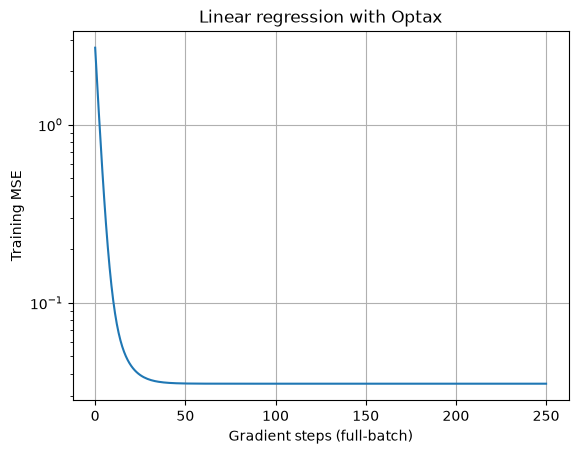

In [17]:
# this function is the same as quadratic_step, but now we pass in data via A_batch and y_batch
# each call to regression_step uses the rows of A_batch and y_batch that you provide
@jax.jit
def regression_step(weights, opt_state, A_batch, y_batch):
    _, gradient = regression_value_and_grad(weights, A_batch, y_batch)
    updates, opt_state = optimizer.update(gradient, opt_state, weights)
    weights = optax.apply_updates(weights, updates)
    return weights, opt_state


# initialize weights, optimizer, and set number of epochs
weights   = jnp.zeros(A_train.shape[1])
opt_state = optimizer.init(weights)
epochs = 250

# the loss before any parameter updates
train_mse_history = [loss(weights, A_train, y_train)]

# here we learn the weights 
for _ in range(epochs):
    weights, opt_state = regression_step(weights, opt_state, A_train, y_train)
    train_mse_history.append(loss(weights, A_train, y_train))

print("Learned weights [a, b]:", weights)
print("Data-generating values: ", [a_true, b_true])

plt.semilogy(np.arange(epochs + 1), train_mse_history)
plt.xlabel("Gradient steps (full-batch)")
plt.ylabel("Training MSE")
plt.title("Linear regression with Optax")
plt.grid(True)
plt.show()

In [18]:
# lets solve the least square problem using the normal equations, and compare to the JAX optimized result
weights_ls = np.linalg.lstsq(np.asarray(A_train), np.asarray(y_train), rcond=None)[0]
print("Least-squares weights:", weights_ls)
print("Optax weights:        ", np.asarray(weights))
print("Weight error norm:   ", np.linalg.norm(np.asarray(weights) - weights_ls))

Least-squares weights: [ 1.51862193 -0.81734837]
Optax weights:         [ 1.51862193 -0.81734837]
Weight error norm:    4.200766132837974e-09


# Computational lab starts here! (Required)

Complete the three exercises below.

Please show me both the code and the requested plots/results. 

For Homework 6, the idea is to reuse these same pieces with a larger polynomial model and many more training steps.

### Exercise 1: Sanity-check the model and loss

Construct the exact, noiseless dataset 

$$y=1+x+x^2$$ 

on 5 points in $[0,1]$. Use `design_matrix(x, degree=2)` and the known weights $\boldsymbol{\omega}=(1,1,1)$.

1. Check that `model(weights, A)` reproduces the example values at your 5 example x values.
2. Check that `loss(weights, A, y)` is zero (exact weights should be zero loss)
3. Check that `jax.grad(loss)(weights, A, y)` is the zero vector (because you're at a minimum)

**HW6 asks you to provide evidence that your model and loss functions work correctly. This is how to do it**

In [21]:
x_check = jnp.linspace(0.0, 1.0, 5)
y_check = 1.0 + x_check + x_check**2

A_check       = design_matrix(x_check, degree=2)
weights_check = jnp.array([1.0, 1.0, 1.0])
print("A_check.shape:", A_check.shape)

y_model = model(weights_check, A_check)
print("\nx values:      ", x_check)
print("model output:  ", y_model)
print("exact y values:", y_check)
print("max |model - y|:", jnp.max(jnp.abs(y_model - y_check)))
print("model matches y:", jnp.allclose(y_model, y_check))

loss_check = loss(weights_check, A_check, y_check)
print("\nloss at exact weights:", loss_check)
print("loss is ~0:", jnp.isclose(loss_check, 0.0))

grad_check = jax.grad(loss)(weights_check, A_check, y_check)
print("\ngradient at exact weights:", grad_check)
print("gradient is ~0:", jnp.allclose(grad_check, 0.0))

A_check.shape: (5, 3)

x values:       [0.   0.25 0.5  0.75 1.  ]
model output:   [1.     1.3125 1.75   2.3125 3.    ]
exact y values: [1.     1.3125 1.75   2.3125 3.    ]
max |model - y|: 0.0
model matches y: True

loss at exact weights: 0.0
loss is ~0: True

gradient at exact weights: [-0. -0. -0.]
gradient is ~0: True


### Exercise 2: Plot training and testing error

Repeat the training loop we did above. Starting from zero weights

1. Log both testing and training MSE values after each update/epoch
2. Plot training and testing MSE vs. step on the same figure
3. Print $\|\boldsymbol{\omega}_{\mathrm{final}}-\boldsymbol{\omega}_{\mathrm{True}}\|_2$. How close are you to the true solution of this optimization problem.

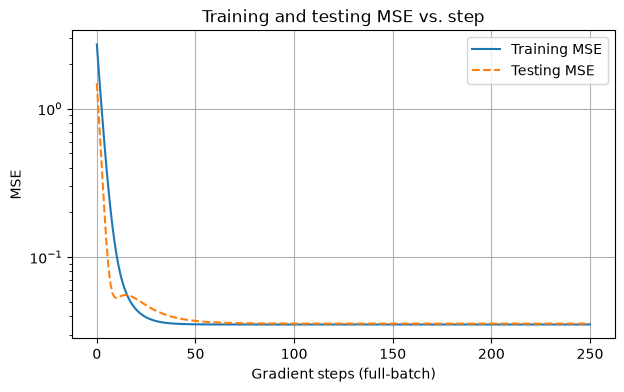

Final training MSE: 0.03516970937924871
Final testing MSE:  0.035641137415924604

Final weights [a, b]:       [ 1.51862193 -0.81734837]
Least-squares weights:      [ 1.51862193 -0.81734837]
||w_final - w_ls||_2      = 4.200766132837974e-09
||w_final - w_true||_2    = 0.025450777795689595


In [22]:
weights_2   = jnp.zeros(A_train.shape[1])
opt_state_2 = optimizer.init(weights_2)
epochs      = 250

train_mse_history_2 = [loss(weights_2, A_train, y_train)]
test_mse_history_2  = [loss(weights_2, A_test,  y_test)]

for _ in range(epochs):
    weights_2, opt_state_2 = regression_step(weights_2, opt_state_2, A_train, y_train)
    train_mse_history_2.append(loss(weights_2, A_train, y_train))
    test_mse_history_2.append(loss(weights_2, A_test,  y_test))

train_mse_history_2 = np.asarray(train_mse_history_2)
test_mse_history_2  = np.asarray(test_mse_history_2)

steps = np.arange(epochs + 1)
plt.figure(figsize=(7, 4))
plt.semilogy(steps, train_mse_history_2, label="Training MSE")
plt.semilogy(steps, test_mse_history_2, "--", label="Testing MSE")
plt.xlabel("Gradient steps (full-batch)")
plt.ylabel("MSE")
plt.title("Training and testing MSE vs. step")
plt.grid(True)
plt.legend()
plt.show()

print("Final training MSE:", train_mse_history_2[-1])
print("Final testing MSE: ", test_mse_history_2[-1])

# Compare final weights with the exact least-squares solution of the optimization problem
w_final = np.asarray(weights_2)
print("\nFinal weights [a, b]:      ", w_final)
print("Least-squares weights:     ", weights_ls)
print("||w_final - w_ls||_2      =", np.linalg.norm(w_final - weights_ls))

# For reference: distance to the data-generating values (not zero, because the data are noisy)
w_true = np.array([a_true, b_true])
print("||w_final - w_true||_2    =", np.linalg.norm(w_final - w_true))

**Exercise 2 discussion.** Both curves drop quickly and level off. The testing MSE settles close to the training MSE, which is about the noise variance ($0.2^2 = 0.04$); a straight line can't fit the noise, so neither error goes to zero. The final weights match the least-squares solution $\boldsymbol{\omega}_{\mathrm{LS}}$ to about $10^{-9}$, so gradient descent has solved the optimization problem to essentially machine-level accuracy for this number of steps. The distance to the data-generating values $(1.5, -0.8)$ is larger (about $0.025$) because noise moves the least-squares minimizer away from those values, and no optimizer can remove that gap.

# Going further (not part of lab, hint for hw 6): neural networks

Consider a one-hidden-layer network:

$$
\hat f(t)=\sum_{j=1}^{m} a_j\,\operatorname{ReLU}(w_j t+b_j)+c.
$$

The parameters are now four arrays/scalars instead of a single weight vector. JAX can still differentiate them together when they are stored in a **dictionary**. The next cell computes just one gradient and one optimizer update; training a network is left for the homework.

In [23]:
def relu_network(params, t):
    hidden = jax.nn.relu(t[:, None] * params["w"][None, :] + params["b"][None, :])
    return hidden @ params["a"] + params["c"]

def neural_loss(params, t, y):
    return jnp.mean((relu_network(params, t) - y)**2)

m = 8
params = {
    "w": jnp.ones(m),
    "b": jnp.linspace(-1.0, 1.0, m),
    "a": jnp.full(m, 0.05),
    "c": jnp.array(0.0),
}

t_nn = jnp.linspace(0.0, 1.0, 50)
y_nn = jnp.exp(-3 * t_nn) * jnp.sin(8 * jnp.pi * t_nn)

nn_grad              = jax.grad(neural_loss)(params, t_nn, y_nn)
nn_optimizer         = optax.adam(learning_rate=0.01)
nn_state             = nn_optimizer.init(params)
nn_updates, nn_state = nn_optimizer.update(nn_grad, nn_state, params)
params_next          = optax.apply_updates(params, nn_updates)

print("Loss before:", neural_loss(params, t_nn, y_nn))
print("Loss after one step:", neural_loss(params_next, t_nn, y_nn))
print("Number of trainable parameters:", sum(x.size for x in jax.tree_util.tree_leaves(params)))

Loss before: 0.13933819881996123
Loss after one step: 0.11247108529238553
Number of trainable parameters: 25


## What to show Scott

**Required for this lab:**

1. Your machine/kernel information from Part I.
2. The three sanity checks from Exercise 1.
3. A single plot containing both training and testing MSE from exercise 2.

You may work in groups. If you finish after class, upload your completed notebook to your GitHub repository and email Scott.